# Análisis exploratorio para entender los datos

In [ ]:
# Configurar Spark 

import os, sys
from pathlib import Path

# Fija el Python del venv para los workers (evita el error de Windows)
os.environ["PYSPARK_PYTHON"] = sys.executable   
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

from pyspark.sql import SparkSession, functions as F, types as T

ROOT = Path.cwd().parent          # el notebook vive en notebooks/
DATA_RAW = ROOT / "data" / "raw"

spark = (
    SparkSession.builder
    .appName("MIND-EDA")
    .master("local[*]")
    .config("spark.driver.memory", "4g")
    .config("spark.sql.shuffle.partitions", "32")   # 2 × hilos; el default (200) es para clústeres
    .config("spark.sql.session.timeZone", "UTC")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("WARN")
print("Spark:", spark.version, "| Python:", sys.version.split()[0])
print("DATA_RAW existe:", DATA_RAW.exists(), "->", DATA_RAW)

Spark: 4.0.2 | Python: 3.11.0
DATA_RAW existe: True -> c:\DevProjects\MMDS\RecSysMIND\data\raw


In [58]:
# Prueba de Spark 
print(spark.range(3).rdd.map(lambda r: r.id * 2).collect())

for p in sorted(DATA_RAW.rglob("*")):
    if p.is_file():
        print(f"{str(p.relative_to(ROOT)):55s} {p.stat().st_size/1e6:8.1f} MB")

[0, 2, 4]
data\raw\MINDsmall_dev\behaviors.tsv                        42.8 MB
data\raw\MINDsmall_dev\entity_embedding.vec                 22.0 MB
data\raw\MINDsmall_dev\news.tsv                             33.5 MB
data\raw\MINDsmall_dev\relation_embedding.vec                1.0 MB
data\raw\MINDsmall_dev.zip                                  30.9 MB
data\raw\MINDsmall_train\behaviors.tsv                      92.0 MB
data\raw\MINDsmall_train\entity_embedding.vec               25.8 MB
data\raw\MINDsmall_train\news.tsv                           41.2 MB
data\raw\MINDsmall_train\relation_embedding.vec              1.0 MB
data\raw\MINDsmall_train.zip                                53.0 MB


In [59]:
# Nombres a asignar a las columnas 
NEWS_COLS = ["news_id", "category", "subcategory", "title", "abstract",
             "url", "title_entities", "abstract_entities"]
BEH_COLS = ["impression_id", "user_id", "time", "history", "impressions"]

# Definición de los tipos de los datos como string
def schema(cols):
    return T.StructType([T.StructField(c, T.StringType(), True) for c in cols])

# Función para leer el archivo con Spark
def read_tsv(path, cols):
    # quote = \u0000 desactiva el manejo de comillas que alguno de los títulos contienen "
    # y Spark partiría mal las filas
    return (spark.read
            .option("sep", "\t").option("header", False)
            .option("quote", "\u0000") # Para manejar comillas 
            .schema(schema(cols))
            .csv(str(path)))

def load_split(split):
    d = DATA_RAW / f"MINDsmall_{split}"
    news = read_tsv(d / "news.tsv", NEWS_COLS).withColumn("split", F.lit(split))
    beh = (read_tsv(d / "behaviors.tsv", BEH_COLS)
           .withColumn("time", F.to_timestamp("time", "M/d/yyyy h:mm:ss a"))
           .withColumn("split", F.lit(split)))
    return news, beh

news_tr, beh_tr = load_split("train")
news_dev, beh_dev = load_split("dev")

for df in (news_tr, beh_tr, news_dev, beh_dev):
    df.cache()

beh_tr.show(3, truncate=80)
news_tr.select("news_id", "category", "subcategory", "title").show(3, truncate=60)

+-------------+-------+-------------------+--------------------------------------------------------------------------------+--------------------------------------------------------------------------------+-----+
|impression_id|user_id|               time|                                                                         history|                                                                     impressions|split|
+-------------+-------+-------------------+--------------------------------------------------------------------------------+--------------------------------------------------------------------------------+-----+
|            1| U13740|2019-11-11 09:05:58|                  N55189 N42782 N34694 N45794 N18445 N63302 N10414 N19347 N31801|                                                               N55689-1 N35729-0|train|
|            2| U91836|2019-11-12 18:11:30|N31739 N6072 N63045 N23979 N35656 N43353 N8129 N1569 N17686 N13008 N21623 N62...|N20678-0 N39317-0 N58114-0 N

In [60]:
def resumen_behaviors(beh, nombre):
    return beh.agg(
        F.count("*").alias("impresiones"),
        F.countDistinct("user_id").alias("usuarios"),
        F.sum(F.col("history").isNull().cast("int")).alias("historial_vacio"),
        F.sum(F.col("time").isNull().cast("int")).alias("time_nulo"),
        F.min("time").alias("desde"),
        F.max("time").alias("hasta"),
    ).withColumn("split", F.lit(nombre))

resumen_behaviors(beh_tr, "train").unionByName(resumen_behaviors(beh_dev, "dev")).show(truncate=False)

# news.tsv de train y dev se juntan para contar el catálogo unificado sin duplicados
news_all = news_tr.unionByName(news_dev).dropDuplicates(["news_id"]).cache()
print("Noticias train:", news_tr.count(), "| dev:", news_dev.count(),
      "| total noticias únicas:", news_all.count())

news_all.select(
    *[F.sum((F.col(c).isNull() | (F.trim(F.col(c)) == "")).cast("int")).alias(f"{c}_vacio")
      for c in ["title", "abstract"]]
).show()

+-----------+--------+---------------+---------+-------------------+-------------------+-----+
|impresiones|usuarios|historial_vacio|time_nulo|desde              |hasta              |split|
+-----------+--------+---------------+---------+-------------------+-------------------+-----+
|156965     |50000   |3238           |0        |2019-11-09 00:00:19|2019-11-14 23:59:13|train|
|73152      |50000   |2214           |0        |2019-11-15 00:00:01|2019-11-15 23:58:03|dev  |
+-----------+--------+---------------+---------+-------------------+-------------------+-----+

Noticias train: 51282 | dev: 42416 | total noticias únicas: 65238
+-----------+--------------+
|title_vacio|abstract_vacio|
+-----------+--------------+
|          0|          3415|
+-----------+--------------+



In [61]:
news_all.select(
    *[F.sum((F.col(c).isNull() | F.trim(F.col(c)).isin("", "[]")).cast("int")).alias(f"{c}_vacio")
      for c in ["title_entities", "abstract_entities"]]
).show()

+--------------------+-----------------------+
|title_entities_vacio|abstract_entities_vacio|
+--------------------+-----------------------+
|               17111|                  17072|
+--------------------+-----------------------+



In [62]:
# Verificar si el historial de un usuario varia de impresión a impresión dentro de cada split
beh_all = beh_tr.unionByName(beh_dev)

beh_feat = (
    beh_all
    .withColumn("hist_len", F.when(F.col("history").isNull(), 0)
                             .otherwise(F.size(F.split("history", " "))))
    .withColumn("cands", F.split("impressions", " "))
    .withColumn("imp_len", F.size("cands"))
    .withColumn("n_clicks", F.size(F.filter("cands", lambda c: c.endswith("-1"))))
    .drop("cands")
).cache()

# ¿El historial es constante por usuario dentro de cada split?
(beh_feat.groupBy("split", "user_id")
    .agg(F.countDistinct("history").alias("n_hist"))
    .groupBy("split")
    .agg(F.sum((F.col("n_hist") > 1).cast("int")).alias("usuarios_con_historial_variable"))
    .show())

+-----+-------------------------------+
|split|usuarios_con_historial_variable|
+-----+-------------------------------+
|train|                              0|
|  dev|                              0|
+-----+-------------------------------+



In [63]:
# Estadísticas descriptivas

def describir(df, col):
    return df.groupBy("split").agg(
        F.round(F.mean(col), 2).alias("media"),
        F.percentile_approx(col, [0.25, 0.5, 0.75, 0.95, 0.99]).alias("p25_p50_p75_p95_p99"),
        F.min(col).alias("min"),
        F.max(col).alias("max"),
    ).orderBy("split", ascending=False)

usuarios = beh_feat.dropDuplicates(["split", "user_id"])   # historial: una fila por usuario

print("Longitud del historial (por usuario)")
describir(usuarios, "hist_len").show(truncate=False)

print("Candidatas por impresión")
describir(beh_feat, "imp_len").show(truncate=False)

print("Clics por impresión")
describir(beh_feat, "n_clicks").show(truncate=False)

print("CTR global (clics / candidatas mostradas)")
(beh_feat.groupBy("split")
    .agg(F.round(F.sum("n_clicks") / F.sum("imp_len"), 4).alias("ctr"))
    .show())

Longitud del historial (por usuario)
+-----+-----+--------------------+---+---+
|split|media|p25_p50_p75_p95_p99 |min|max|
+-----+-----+--------------------+---+---+
|train|18.52|[5, 11, 22, 61, 116]|0  |558|
|dev  |25.52|[7, 15, 32, 84, 150]|0  |444|
+-----+-----+--------------------+---+---+

Candidatas por impresión
+-----+-----+----------------------+---+---+
|split|media|p25_p50_p75_p95_p99   |min|max|
+-----+-----+----------------------+---+---+
|train|37.23|[10, 24, 51, 118, 165]|2  |299|
|dev  |37.47|[10, 23, 51, 119, 182]|2  |295|
+-----+-----+----------------------+---+---+

Clics por impresión
+-----+-----+-------------------+---+---+
|split|media|p25_p50_p75_p95_p99|min|max|
+-----+-----+-------------------+---+---+
|train|1.51 |[1, 1, 2, 4, 6]    |1  |35 |
|dev  |1.52 |[1, 1, 2, 4, 6]    |1  |24 |
+-----+-----+-------------------+---+---+

CTR global (clics / candidatas mostradas)
+-----+------+
|split|   ctr|
+-----+------+
|train|0.0404|
|  dev|0.0406|
+-----+------+



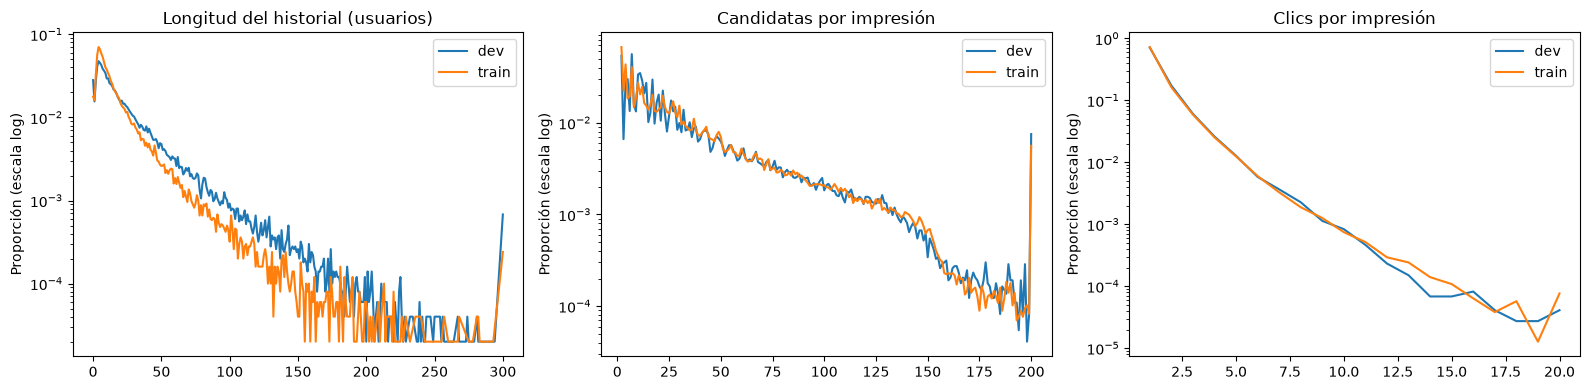

In [64]:
import matplotlib.pyplot as plt

FIG = ROOT / "results" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

def hist_por_split(df, col, ax, titulo, tope):
    # Agrega en Spark y trae solo los conteos (pocas filas) a pandas.
    # Los valores > tope se agrupan en el último punto.
    pdf = (df.withColumn(col, F.least(F.col(col), F.lit(tope)))
             .groupBy("split", col).count()
             .toPandas())
    for split, g in pdf.groupby("split"):
        g = g.sort_values(col)
        ax.plot(g[col], g["count"] / g["count"].sum(), label=split)
    ax.set_yscale("log")
    ax.set_title(titulo)
    ax.set_ylabel("Proporción (escala log)")
    ax.legend()

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
hist_por_split(usuarios, "hist_len", axes[0], "Longitud del historial (usuarios)", tope=300)
hist_por_split(beh_feat, "imp_len", axes[1], "Candidatas por impresión", tope=200)
hist_por_split(beh_feat, "n_clicks", axes[2], "Clics por impresión", tope=20)
plt.tight_layout()
plt.savefig(FIG / "eda_distribuciones.png", dpi=150)
plt.show()

In [65]:
# 1. Usuarios compartidos entre train y dev, y si su historial coincide
u_tr  = beh_feat.filter("split = 'train'").select("user_id", F.coalesce("history", F.lit("")).alias("h_tr")).dropDuplicates(["user_id"])
u_dev = beh_feat.filter("split = 'dev'").select("user_id", F.coalesce("history", F.lit("")).alias("h_dev")).dropDuplicates(["user_id"])

(u_tr.join(u_dev, "user_id")
    .agg(F.count("*").alias("usuarios_en_ambos"),
         F.sum((F.col("h_tr") == F.col("h_dev")).cast("int")).alias("historial_identico"),
         F.sum(F.col("h_dev").startswith(F.col("h_tr")).cast("int")).alias("dev_empieza_con_train"))
    .show())

print("Usuarios solo en train:", u_tr.join(u_dev, "user_id", "left_anti").count())
print("Usuarios solo en dev:  ", u_dev.join(u_tr, "user_id", "left_anti").count())

# 2. Criterio de ≥ 5 clics: historial + clics en impresiones (train + dev)
por_usuario = (beh_feat.groupBy("user_id")
               .agg(F.max("hist_len").alias("hist_len"),
                    F.sum("n_clicks").alias("clics_impresiones"))
               .withColumn("clics_totales", F.col("hist_len") + F.col("clics_impresiones")))

por_usuario.agg(
    F.count("*").alias("usuarios"),
    F.sum((F.col("clics_totales") < 5).cast("int")).alias("menos_de_5_clics_totales"),
    F.sum((F.col("hist_len") < 5).cast("int")).alias("menos_de_5_en_historial"),
).show()

+-----------------+------------------+---------------------+
|usuarios_en_ambos|historial_identico|dev_empieza_con_train|
+-----------------+------------------+---------------------+
|             5943|              5943|                 5943|
+-----------------+------------------+---------------------+

Usuarios solo en train: 44057
Usuarios solo en dev:   44057
+--------+------------------------+-----------------------+
|usuarios|menos_de_5_clics_totales|menos_de_5_en_historial|
+--------+------------------------+-----------------------+
|   94057|                    6702|                  16841|
+--------+------------------------+-----------------------+



In [66]:
tiene_t = F.trim(F.coalesce("title_entities", F.lit("[]"))) != "[]"
tiene_a = F.trim(F.coalesce("abstract_entities", F.lit("[]"))) != "[]"

news_all.agg(
    F.count("*").alias("noticias"),
    F.sum((tiene_t | tiene_a).cast("int")).alias("con_alguna_entidad"),
    F.sum((~tiene_t & ~tiene_a).cast("int")).alias("sin_entidades"),
).show()

+--------+------------------+-------------+
|noticias|con_alguna_entidad|sin_entidades|
+--------+------------------+-------------+
|   65238|             57054|         8184|
+--------+------------------+-------------+



In [67]:
# Transformación de los datos de comportamiento a formato largo (una fila por noticia candidata mostrada,
#  con su label de clic)

imp_long = (
    beh_all
    .select("impression_id", "user_id", "time", "split",
            F.explode(F.split("impressions", " ")).alias("item"))
    .withColumn("news_id", F.split("item", "-")[0])
    .withColumn("label", F.split("item", "-")[1].cast("int"))
    .drop("item")
).cache()

imp_long.groupBy("split").agg(
    F.count("*").alias("filas"),
    F.sum("label").alias("clics"),
).show()

# Control: toda noticia mostrada debe existir en el catálogo
print("Noticias mostradas sin metadatos:",
      imp_long.join(news_all, "news_id", "left_anti").select("news_id").distinct().count())

+-----+-------+------+
|split|  filas| clics|
+-----+-------+------+
|train|5843444|236344|
|  dev|2740998|111383|
+-----+-------+------+

Noticias mostradas sin metadatos: 0


In [68]:
# Estadísticas por categoría de noticias
cats = (
    imp_long.join(news_all.select("news_id", "category"), "news_id")
    .groupBy("category")
    .agg(F.count("*").alias("mostradas"), F.sum("label").alias("clics"))
    .join(news_all.groupBy("category").agg(F.count("*").alias("noticias_catalogo")), "category")
)

tot = cats.agg(F.sum("noticias_catalogo"), F.sum("mostradas"), F.sum("clics")).first()

cats_pdf = (
    cats.withColumn("pct_catalogo", F.round(100 * F.col("noticias_catalogo") / tot[0], 2))
        .withColumn("pct_mostradas", F.round(100 * F.col("mostradas") / tot[1], 2))
        .withColumn("pct_clics", F.round(100 * F.col("clics") / tot[2], 2))
        .withColumn("ctr", F.round(F.col("clics") / F.col("mostradas"), 4))
        .orderBy(F.desc("clics"))
        .toPandas()
)
cats_pdf

,category,mostradas,clics,noticias_catalogo,pct_catalogo,pct_mostradas,pct_clics,ctr
0,news,2232125,95172,20039,30.72,26.00,27.37,0.0426
1,sports,942187,54220,19368,29.69,10.98,15.59,0.0575
2,lifestyle,1016267,45431,2991,4.58,11.84,13.07,0.0447
3,finance,789133,24610,3786,5.80,9.19,7.08,0.0312
4,tv,374229,20176,1027,1.57,4.36,5.80,0.0539
5,music,358613,19776,902,1.38,4.18,5.69,0.0551
6,foodanddrink,572554,17579,3123,4.79,6.67,5.06,0.0307
7,health,441673,15331,2207,3.38,5.15,4.41,0.0347
8,entertainment,464494,13362,695,1.07,5.41,3.84,0.0288
9,travel,446318,10858,3013,4.62,5.20,3.12,0.0243


In [69]:
# Estadisticas de longitud de título y abstract (número de palabras)

def n_palabras(c):
    txt = F.trim(F.coalesce(F.col(c), F.lit("")))
    return F.when(txt == "", 0).otherwise(F.size(F.split(txt, r"\s+")))

textos = news_all.select(n_palabras("title").alias("titulo"),
                         n_palabras("abstract").alias("abstract"))

textos.select(
    *[F.round(F.mean(c), 1).alias(f"{c}_media") for c in ["titulo", "abstract"]],
    *[F.percentile_approx(c, [0.05, 0.5, 0.95]).alias(f"{c}_p5_p50_p95") for c in ["titulo", "abstract"]],
    F.max("abstract").alias("abstract_max"),
).show(truncate=False)

+------------+--------------+-----------------+-------------------+------------+
|titulo_media|abstract_media|titulo_p5_p50_p95|abstract_p5_p50_p95|abstract_max|
+------------+--------------+-----------------+-------------------+------------+
|10.7        |34.9          |[6, 10, 16]      |[0, 25, 78]        |474         |
+------------+--------------+-----------------+-------------------+------------+



In [70]:
# Evaluar magnitud arranque en frío

# --- Ítems: ¿qué "ve" cada modelo durante el entrenamiento? ---
# ALS implícito usa interacciones positivas: historiales (train y dev, anteriores a la impresión)
# + clics en impresiones de train. La popularidad usa clics de train.
hist_items = (beh_all.select(F.explode(F.split("history", " ")).alias("news_id"))
              .distinct().withColumn("en_hist", F.lit(1)))
clic_tr = (imp_long.filter("split = 'train' AND label = 1")
           .select("news_id").distinct().withColumn("clic_tr", F.lit(1)))

dev = (imp_long.filter("split = 'dev'")
       .join(hist_items, "news_id", "left")
       .join(clic_tr, "news_id", "left")
       .fillna(0, subset=["en_hist", "clic_tr"])
       .withColumn("fria_als", 1 - F.greatest("en_hist", "clic_tr"))   # sin vector ALS
       .withColumn("fria_pop", 1 - F.col("clic_tr"))                   # popularidad = 0
      ).cache()

print("Nivel candidata (filas de dev)")
dev.agg(
    F.count("*").alias("candidatas"),
    F.round(F.avg("fria_als"), 4).alias("pct_frias_ALS"),
    F.round(F.avg("fria_pop"), 4).alias("pct_frias_pop"),
    F.round(F.sum(F.col("label") * F.col("fria_als")) / F.sum("label"), 4).alias("pct_clics_frios_ALS"),
    F.round(F.sum(F.col("label") * F.col("fria_pop")) / F.sum("label"), 4).alias("pct_clics_frios_pop"),
).show()

print("Nivel noticia (noticias distintas mostradas en dev)")
(dev.select("news_id", "fria_als").distinct()
    .agg(F.count("*").alias("noticias"), F.sum("fria_als").alias("frias_ALS"))
    .show())

print("Nivel impresión: ¿el clic cae en noticias frías?")
(dev.groupBy("impression_id")
    .agg(F.sum("label").alias("clics"),
         F.sum(F.col("label") * F.col("fria_als")).alias("clics_frios"))
    .agg(F.round(F.avg((F.col("clics_frios") == F.col("clics")).cast("int")), 4).alias("imp_todos_clics_frios"),
         F.round(F.avg((F.col("clics_frios") > 0).cast("int")), 4).alias("imp_algun_clic_frio"))
    .show())

# --- Usuarios de dev, por usuario (no por impresión) ---
usr_tr = beh_all.filter("split = 'train'").select("user_id").distinct().withColumn("en_train", F.lit(1))
(beh_feat.filter("split = 'dev'")
    .dropDuplicates(["user_id"])
    .join(usr_tr, "user_id", "left").fillna(0, subset=["en_train"])
    .agg(F.count("*").alias("usuarios_dev"),
         F.sum((F.col("en_train") == 0).cast("int")).alias("no_en_train"),
         F.sum((F.col("hist_len") == 0).cast("int")).alias("sin_historial"),
         F.sum(((F.col("en_train") == 0) & (F.col("hist_len") == 0)).cast("int")).alias("frios_totales"))
    .show())

Nivel candidata (filas de dev)
+----------+-------------+-------------+-------------------+-------------------+
|candidatas|pct_frias_ALS|pct_frias_pop|pct_clics_frios_ALS|pct_clics_frios_pop|
+----------+-------------+-------------+-------------------+-------------------+
|   2740998|        0.523|       0.5486|             0.4878|             0.5136|
+----------+-------------+-------------+-------------------+-------------------+

Nivel noticia (noticias distintas mostradas en dev)
+--------+---------+
|noticias|frias_ALS|
+--------+---------+
|    5369|     3272|
+--------+---------+

Nivel impresión: ¿el clic cae en noticias frías?
+---------------------+-------------------+
|imp_todos_clics_frios|imp_algun_clic_frio|
+---------------------+-------------------+
|               0.4135|             0.5549|
+---------------------+-------------------+

+------------+-----------+-------------+-------------+
|usuarios_dev|no_en_train|sin_historial|frios_totales|
+------------+-----------

+-----+------------------+---------------+--------------+--------------+---------------+---------------+
|split|noticias_mostradas|sin_ningun_clic|clics_top_1pct|clics_top_5pct|clics_top_10pct|clics_top_20pct|
+-----+------------------+---------------+--------------+--------------+---------------+---------------+
|train|             20288|          12575|         0.516|         0.833|          0.935|          0.981|
|  dev|              5369|           3157|         0.607|         0.884|          0.952|          0.985|
+-----+------------------+---------------+--------------+--------------+---------------+---------------+



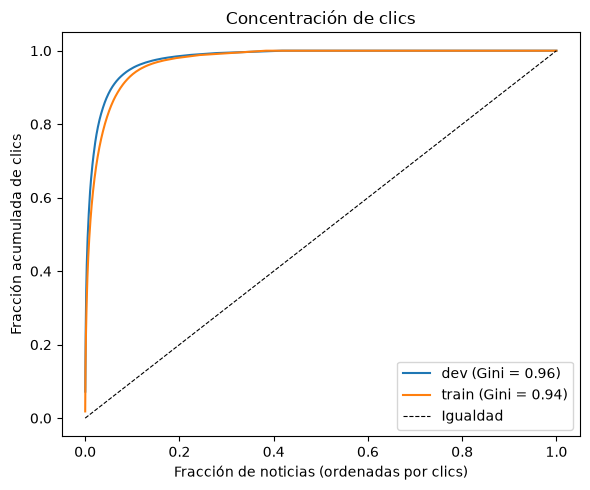

In [71]:
# distribución de clics por noticia - popularidad
from pyspark.sql import Window
import numpy as np

pop = (imp_long.groupBy("split", "news_id")
       .agg(F.sum("label").alias("clics"), F.count("*").alias("exposiciones")))

w_rank = Window.partitionBy("split").orderBy(F.desc("clics"))
w_split = Window.partitionBy("split")

conc = (pop
        .withColumn("rank", F.row_number().over(w_rank))
        .withColumn("n", F.count("*").over(w_split))
        .withColumn("total", F.sum("clics").over(w_split))
        .withColumn("pct_noticias", F.col("rank") / F.col("n"))
        .withColumn("pct_clics_acum",
                    F.sum("clics").over(w_rank.rowsBetween(Window.unboundedPreceding, 0)) / F.col("total"))
       ).cache()

conc.groupBy("split").agg(
    F.first("n").alias("noticias_mostradas"),
    F.sum((F.col("clics") == 0).cast("int")).alias("sin_ningun_clic"),
    *[F.round(F.max(F.when(F.col("pct_noticias") <= p, F.col("pct_clics_acum"))), 3)
        .alias(f"clics_top_{int(p*100)}pct") for p in [0.01, 0.05, 0.10, 0.20]],
).orderBy("split", ascending=False).show()

# Curva de concentración + Gini (con pocas miles de filas, pandas basta)
pdf = conc.select("split", "pct_noticias", "pct_clics_acum").toPandas()
fig, ax = plt.subplots(figsize=(6, 5))
for split, g in pdf.groupby("split"):
    g = g.sort_values("pct_noticias")
    gini = 2 * np.trapezoid(g["pct_clics_acum"], g["pct_noticias"]) - 1
    ax.plot(g["pct_noticias"], g["pct_clics_acum"], label=f"{split} (Gini = {gini:.2f})")
ax.plot([0, 1], [0, 1], "k--", lw=0.8, label="Igualdad")
ax.set_xlabel("Fracción de noticias (ordenadas por clics)")
ax.set_ylabel("Fracción acumulada de clics")
ax.set_title("Concentración de clics")
ax.legend()
plt.tight_layout(); plt.savefig(FIG / "eda_concentracion.png", dpi=150); plt.show()

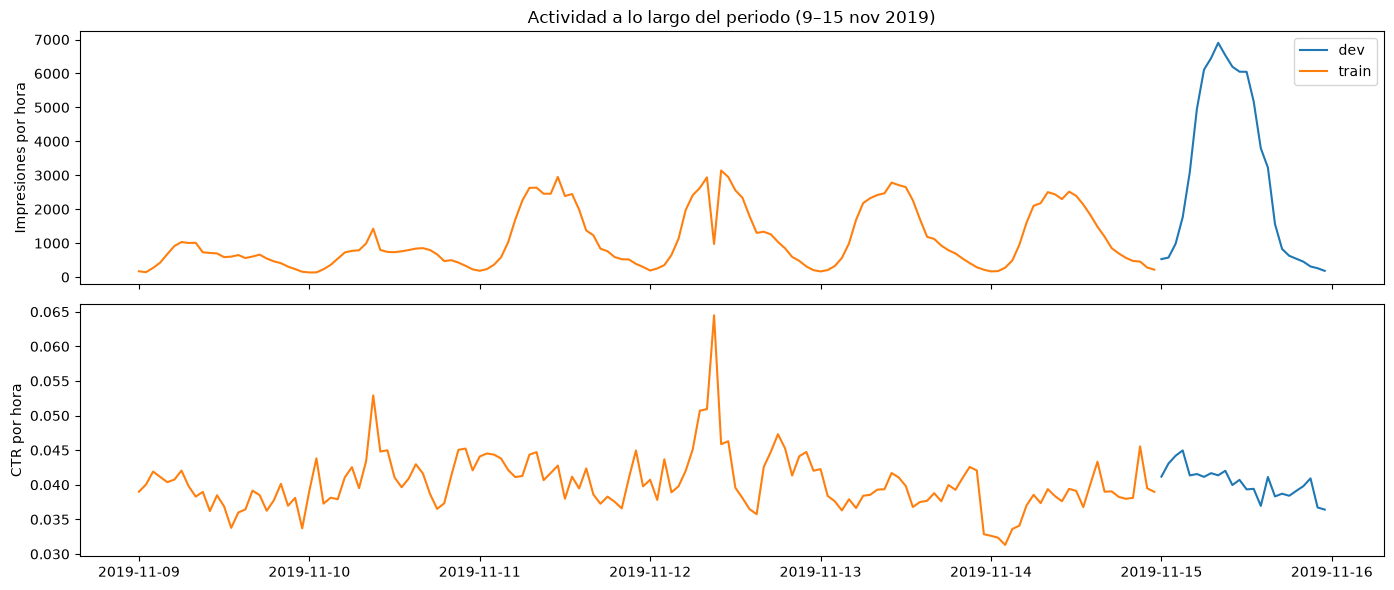

Impresiones por día:
+-----+----------+-----+
|split|       dia|count|
+-----+----------+-----+
|train|2019-11-09|13570|
|train|2019-11-10|15048|
|train|2019-11-11|32799|
|train|2019-11-12|33654|
|train|2019-11-13|31624|
|train|2019-11-14|30270|
|  dev|2019-11-15|73152|
+-----+----------+-----+



In [72]:
por_hora = (beh_feat
            .withColumn("hora", F.date_trunc("hour", "time"))
            .groupBy("split", "hora")
            .agg(F.count("*").alias("impresiones"),
                 F.sum("n_clicks").alias("clics"),
                 F.sum("imp_len").alias("candidatas"))
            .withColumn("ctr", F.col("clics") / F.col("candidatas"))
            .orderBy("hora")
            .toPandas())

fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
for split, g in por_hora.groupby("split"):
    axes[0].plot(g["hora"], g["impresiones"], label=split)
    axes[1].plot(g["hora"], g["ctr"], label=split)
axes[0].set_ylabel("Impresiones por hora"); axes[0].legend()
axes[1].set_ylabel("CTR por hora")
axes[0].set_title("Actividad a lo largo del periodo (9–15 nov 2019)")
plt.tight_layout(); plt.savefig(FIG / "eda_temporal.png", dpi=150); plt.show()

print("Impresiones por día:")
(beh_feat.groupBy("split", F.to_date("time").alias("dia")).count().orderBy("dia").show())

+-----+------------------------------------------------------------------------------+----------------------+
|split|edad_h_p25_p50_p75_p90                                                        |pct_clics_primeras_24h|
+-----+------------------------------------------------------------------------------+----------------------+
|train|[8.099444444444444, 14.582222222222223, 21.352222222222224, 38.20722222222222]|0.791                 |
|dev  |[10.438055555555556, 15.016388888888889, 19.59027777777778, 45.865]           |0.822                 |
+-----+------------------------------------------------------------------------------+----------------------+



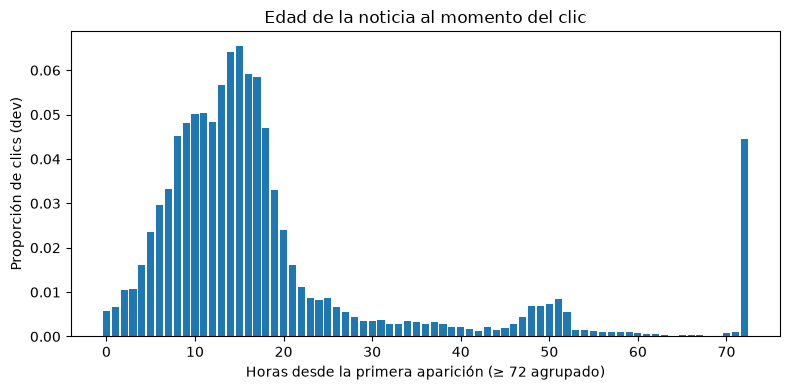

In [73]:
# Edad de las noticias: horas desde la primera vez que la noticia aparece en las impresiones.
# Limitación: los datos empiezan el 9 de nov, así que las noticias anteriores quedan truncadas.
primera_vez = imp_long.groupBy("news_id").agg(F.min("time").alias("primera_vez"))

edad = (imp_long.filter("label = 1")
        .join(primera_vez, "news_id")
        .withColumn("edad_h", (F.unix_timestamp("time") - F.unix_timestamp("primera_vez")) / 3600))

edad.groupBy("split").agg(
    F.percentile_approx("edad_h", [0.25, 0.5, 0.75, 0.9]).alias("edad_h_p25_p50_p75_p90"),
    F.round(F.avg((F.col("edad_h") <= 24).cast("int")), 3).alias("pct_clics_primeras_24h"),
).orderBy("split", ascending=False).show(truncate=False)

edad_pdf = (edad.filter("split = 'dev'")
            .withColumn("hora_desde_inicio", F.floor(F.least("edad_h", F.lit(72))))
            .groupBy("hora_desde_inicio").count().orderBy("hora_desde_inicio").toPandas())

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(edad_pdf["hora_desde_inicio"], edad_pdf["count"] / edad_pdf["count"].sum())
ax.set_xlabel("Horas desde la primera aparición (≥ 72 agrupado)")
ax.set_ylabel("Proporción de clics (dev)")
ax.set_title("Edad de la noticia al momento del clic")
plt.tight_layout(); plt.savefig(FIG / "eda_edad_clic.png", dpi=150); plt.show()

# Resumen de hallazgos del EDA (MIND-small)

## 1. Estructura de los datos

- **Train:** 156.965 impresiones entre el 9 y el 14 de noviembre de 2019. **Dev:** 73.152 impresiones del 15 de noviembre. Dev corresponde a un solo día de validación, no a una semana de test.
- **Usuarios:** 50.000 por conjunto, con 5.943 usuarios compartidos y 94.057 usuarios únicos en total. Los usuarios parecen haberse seleccionado por separado.
- **Historiales:** cada usuario tiene un historial fijo, que no incluye los clics del periodo analizado.
- **Criterio de ≥ 5 clics:** 6.702 usuarios (7 %) tienen menos de cinco clics sumando historial e impresiones. No es posible verificar el criterio original en MIND-small debido al submuestreo.
- **Formato largo:** 5,84 millones de pares usuario-noticia en train y 2,74 millones en dev. Todas las noticias mostradas tienen metadatos.

## 2. Impresiones e historiales

- **Longitud del historial:** mediana de 11 noticias en train y 15 en dev. La diferencia responde a las poblaciones seleccionadas, no a un crecimiento de los historiales.
- **Candidatas por impresión:** mediana de 24 noticias, con un rango de 2 a 299.
- **Clics por impresión:** mediana de 1 y media de 1,5. La mayoría de las impresiones tiene un único clic.
- **CTR:** aproximadamente 4 % en ambos conjuntos, equivalente a un clic por cada 25 noticias mostradas. Esto refleja un fuerte desbalance entre clics y no clics.

## 3. Características del contenido

- **Catálogo:** 65.238 noticias únicas, con solapamiento entre train y dev.
- **Texto:** los títulos tienen una mediana de 10 palabras y los resúmenes de 25. Cerca del 5 % de las noticias no tiene resumen.
- **Entidades:** el 87,5 % de las noticias contiene al menos una entidad en el título o resumen.
- **Categorías:** hay 16 categorías, incluidas dos residuales (*kids* y *northamerica*). La exposición no es proporcional al tamaño del catálogo: *sports* representa el 29,7 % del catálogo, pero solo el 11 % de las noticias mostradas. *Lifestyle* y *entertainment* tienen una exposición entre 2,5 y 5 veces superior a su peso en el catálogo.
- **CTR por categoría:** varía entre el 2,4 % en *travel* y el 5,75 % en *sports*.

Estos resultados muestran que los datos reflejan tanto las interacciones de los usuarios como las decisiones de MSN sobre qué noticias mostrar.

## 4. Arranque en frío

El arranque en frío ocurre cuando el modelo debe recomendar noticias o atender a usuarios sin suficientes interacciones previas.

- **Noticias:** en dev, el 61 % de las noticias mostradas no tiene interacciones previas en los historiales ni en los clics de train. Estas representan el 52 % de las candidatas y el 49 % de los clics.
- **Impresiones:** en el 41 % de las impresiones, todas las noticias que reciben clics son noticias sin interacciones previas.
- **Usuarios:** el 88 % de los usuarios de dev no aparece en train, pero solo el 2,5 % carece también de historial.

El principal problema es la falta de interacciones previas con muchas noticias, más que la ausencia total de información sobre los usuarios.

## 5. Popularidad y comportamiento temporal

- **Concentración:** el 1 % de las noticias recibe el 52 % de los clics en train y el 61 % en dev. El índice de Gini es de 0,94 y 0,96, respectivamente. Entre el 59 % y el 62 % de las noticias mostradas nunca recibe un clic.
- **Vida útil:** entre el 79 % y el 82 % de los clics ocurre durante las primeras 24 horas desde la primera aparición registrada de la noticia. La mediana es de unas 15 horas. Como MIND no incluye la fecha de publicación, la primera aparición se utiliza como aproximación.
- **Patrón diario:** la actividad es menor durante la madrugada y mayor hacia la mitad del día. Los fines de semana registran menos de la mitad de las impresiones de los días laborables.
- **Comparación entre conjuntos:** los volúmenes absolutos de train y dev no son directamente comparables porque cubren periodos diferentes. El CTR se mantiene relativamente estable, entre el 3,5 % y el 4,5 %.

## 6. Implicaciones para el modelado

1. **ALS:** puede aprovechar las interacciones históricas, pero tendrá dificultades con las noticias nuevas. Combinar los historiales disponibles antes de las impresiones con los clics de train permitiría cubrir al 97,5 % de los usuarios de dev, siempre que se evite la fuga de información.

2. **Baseline de popularidad:** la popularidad acumulada de train no identifica bien las noticias nuevas. Conviene compararla con una popularidad reciente, calculada en ventanas de 6 a 48 horas.

3. **Comparación entre conjuntos:** es preferible utilizar tasas normalizadas o calcular la popularidad dentro de cada periodo, en lugar de comparar directamente los conteos absolutos.

4. **Modelo basado en contenido:** el título y el resumen permiten representar noticias sin interacciones previas, por lo que este enfoque complementa a ALS.

5. **Representación textual:** conviene comparar TF-IDF con solo el título frente a TF-IDF con título y resumen. También es viable generar *embeddings* para el catálogo completo.

6. **Categorías:** las diferencias de CTR sugieren que la categoría puede aportar información adicional a un modelo híbrido o a un baseline.

7. **Desbalance:** el CTR del 4 % hace que los ejemplos sin clic sean mucho más numerosos. Puede ser necesario aplicar muestreo de negativos o ponderación en los modelos supervisados.

8. **Validación temporal:** la evaluación debe respetar el orden temporal y evitar el uso de información futura. El 14 de noviembre podría servir como referencia para analizar la comparabilidad con el viernes 15.

9. **Sesgo de exposición:** los modelos aprenden de las noticias que MSN decidió mostrar. Por tanto, los clics no reflejan únicamente las preferencias de los usuarios, sino también las oportunidades de exposición que tuvieron las noticias.

## Conclusión

El EDA identifica tres retos principales: la concentración de clics en pocas noticias, el arranque en frío y el sesgo de exposición.


In [77]:
spark.stop()